In [24]:
import torch
import torch.nn as nn
import torch.optim as optim 
import numpy as np
from tqdm.notebook import tqdm
from PIL import Image, ImageOps

from torchvision import transforms
from torch.utils.data import DataLoader, Dataset

import matplotlib.pyplot as plt
%matplotlib inline

import kagglehub


In [2]:
# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Path to dataset files:", path)

Path to dataset files: /home/hawk/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1


In [3]:
from pathlib import Path

dataset_path = Path(path)

for file in dataset_path.rglob("*"):
    if file.is_file():
        print(file.relative_to(dataset_path))

t10k-labels.idx1-ubyte
train-images.idx3-ubyte
t10k-images.idx3-ubyte
train-labels.idx1-ubyte
train-labels-idx1-ubyte/train-labels-idx1-ubyte
t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
train-images-idx3-ubyte/train-images-idx3-ubyte
t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.get_device_name()

'NVIDIA GeForce RTX 3050 Laptop GPU'

In [5]:
torch.manual_seed(11037)

In [6]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

In [7]:
def load_images(file_path):
    with open(file_path, "rb") as f:
        images = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    return images.reshape(-1, 28, 28)

def load_labels(file_path):
    with open(file_path, "rb") as f:
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return labels

In [8]:
X_train = load_images(dataset_path / "train-images.idx3-ubyte")
Y_train = load_labels(dataset_path / "train-labels.idx1-ubyte")

X_test = load_images(dataset_path / "t10k-images.idx3-ubyte")
Y_test = load_labels(dataset_path / "t10k-labels.idx1-ubyte")

In [9]:
class MNISTDataset(Dataset):

    def __init__(self,images ,labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, key):
        image = self.images[key]
        label = int(self.labels[key])

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [10]:
train_df = MNISTDataset(X_train, Y_train, transform=transform)
test_df = MNISTDataset(X_test, Y_test, transform=transform)

In [11]:
train_loader = DataLoader(train_df, batch_size=64, shuffle=True)
test_loader = DataLoader(test_df, batch_size=64, shuffle=False)

In [12]:
images, labels = next(iter(train_loader))

/nix/store/wzif7pg2cmy12czmfgydd7xw919dy8z5-python3-3.13.15-env/lib/python3.13/site-packages/torchvision/transforms/functional.py:154: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /build/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  img = torch.from_numpy(pic.transpose((2, 0, 1))).contiguous()


In [13]:
images.shape

torch.Size([64, 1, 28, 28])

In [14]:
labels.shape

torch.Size([64])

In [15]:
images.min().item()

-0.4242129623889923

In [16]:
images.max().item()

2.821486711502075

In [17]:
class CNN_test(nn.Module):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.features = nn.Sequential(
                                        nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1), #16, 28, 28
                                        nn.ReLU(),
                                        nn.MaxPool2d(kernel_size=2), #16, 14, 14

                                        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1), #32, 14, 14
                                        nn.ReLU(),
                                        nn.MaxPool2d(kernel_size=2), #32, 7, 7   
                                                                                                                            )

        self.classifier = nn.Sequential(
                                        nn.Flatten(),
                                        nn.Linear(32*7*7, 128),
                                        nn.ReLU(),
                                        nn.Linear(128, 10)
                                                                )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [18]:
model = CNN_test().to(device)
print(model)

CNN_test(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [19]:
Loss = nn.CrossEntropyLoss()
optim = optim.Adam(model.parameters(), lr=0.01)

In [20]:
epochs = 10

train_losses = []
train_accuracy = []
test_losses = []
test_accuracy = []

progress = tqdm(range(epochs), desc="Training Gama", unit="epochs")

for epoch in progress:
    
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optim.zero_grad()

        outputs = model(images)

        loss = Loss(outputs, labels)

        loss.backward()

        optim.step()

        running_loss  += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss  / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracy.append(epoch_accuracy)

    model.eval()
    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = Loss(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    
    val_loss = running_loss / total
    val_accuracy = 100 * correct / total

    test_losses.append(val_loss)
    test_accuracy.append(val_accuracy) 

    progress.set_postfix({"Loss":f"{epoch_loss:.3f},{val_loss:.3f}", "Accuracy":f"{epoch_accuracy:.3f},{val_accuracy:.3f}"})


Training Gama:   0%|          | 0/10 [00:00<?, ?epochs/s]

In [21]:
torch.save(model.state_dict(), "CNN.pth")

In [23]:
dummy_input = torch.rand(1, 1, 28, 28).to(device)

torch.onnx.export(model, (dummy_input,), "CNN.onnx", input_names=["I/P"], output_names=["O/P"], opset_version=18, dynamo=True)

[torch.onnx] Obtain model graph for `CNN_test([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CNN_test([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


/nix/store/wzif7pg2cmy12czmfgydd7xw919dy8z5-python3-3.13.15-env/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 18},
            producer_name='pytorch',
            producer_version='2.11.0',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"I/P"<FLOAT,[1,1,28,28]>
            ),
            outputs=(
                %"O/P"<FLOAT,[1,10]>
            ),
            initializers=(
                %"features.0.weight"<FLOAT,[16,1,3,3]>{TorchTensor(...)},
                %"features.0.bias"<FLOAT,[16]>{TorchTensor(...)},
                %"features.3.weight"<FLOAT,[32,16,3,3]>{TorchTensor(...)},
                %"features.3.bias"<FLOAT,[32]>{TorchTensor(...)},
                %"classifier.1.weight"<FLOAT,[128,1568]>{TorchTensor(...)},
                %"classifier.1.bias"<FLOAT,[128]>{TorchTensor(...)},
                %"classifier.3.weight"<FLOAT,[10,128]>{TorchTensor(...)},
                %"classifier.3.bias"<

In [25]:
image = Image.open("test.png").convert("L")

In [26]:
if np.asarray(image).mean() > 127:
    image = ImageOps.invert(image)

In [33]:
image = image.resize((28,28), Image.Resampling.LANCZOS)
image_tensor = transform(image).unsqueeze(0).to(device)
image_tensor.shape

torch.Size([1, 1, 28, 28])

In [41]:
model.eval()

with torch.no_grad():
    output = model(image_tensor)
    prob = torch.softmax(outputs, dim=1)
    prediction = output.argmax(dim=1).item()

In [42]:
f"prediction {prediction} confidence {prob[0, prediction].item()}"

'prediction 4 confidence 1.1444489676720092e-20'

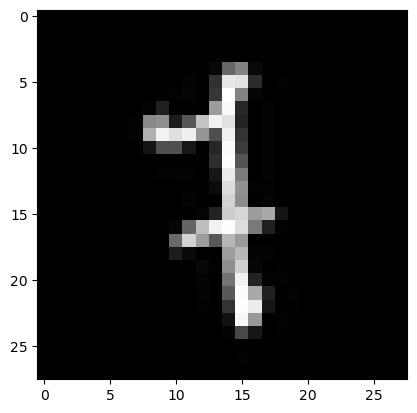

In [43]:
plt.imshow(image, cmap="gray")
plt.show()

In [46]:
prob.size()

torch.Size([32, 10])

In [47]:
for digit, prob0 in enumerate(prob[0]):
    print(f"digit {digit} prob {prob0.item()}")

digit 0 prob 8.65527582917928e-22
digit 1 prob 6.411351517947249e-23
digit 2 prob 1.0
digit 3 prob 2.2014893163654903e-13
digit 4 prob 1.1444489676720092e-20
digit 5 prob 2.8914641379415455e-24
digit 6 prob 5.977503472087317e-28
digit 7 prob 3.852550656963105e-12
digit 8 prob 3.6465772113340126e-15
digit 9 prob 4.6478305228106455e-21
